# E1 — Dataset and evidence characterization

This notebook characterizes the frozen E0 exact-sequence universe before any descriptor-space
or embedding-space analysis.

**Scope**

- dataset counts and composition;
- PhageLysData Core subtype composition;
- independent evidence-membership counts;
- protein-length summaries;
- visual comparison of length distributions by biological label;
- attrition induced by the common `canonical20 + length <= 1024 aa` representation contract.

No statistical hypothesis testing is performed here. Those analyses begin in later EDA stages.

**Input**

`EDA_results/E0/phagelytic_eda_universe.csv`

**Main outputs**

- `EDA_results/E1/dataset_composition.tsv`
- `EDA_results/E1/length_summary.tsv`
- `EDA_results/E1/representation_coverage.tsv`
- `EDA_results/E1/figures/*.png`
- `EDA_results/E1/figures/*.pdf`

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.05,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

## 1. Paths and input

In [3]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = PROJECT_ROOT / "EDA_results" / "E0" / "phagelytic_eda_universe.csv"

RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E1"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not E0_PATH.is_file():
    raise FileNotFoundError(f"E0 input not found: {E0_PATH}")

print(f"Project root : {PROJECT_ROOT}")
print(f"E0 input     : {E0_PATH}")
print(f"E1 results   : {RESULT_DIR}")

Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
E0 input     : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E0/phagelytic_eda_universe.csv
E1 results   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1


In [4]:
df = pd.read_csv(
    E0_PATH,
    dtype={
        "sequence_uid": str,
        "sequence": str,
        "sequence_length": "int64",
        "phage_lytic": str,
        "phage_lytic_subtype": str,
        "clean_subtype": str,
        "sequence_state": str,
        "pnu_role": str,
        "stratum": str,
    },
    low_memory=False,
)

EXPECTED_ROWS = 442_329

assert len(df) == EXPECTED_ROWS, f"Unexpected E0 size: {len(df):,}"
assert df["sequence"].is_unique
assert df["sequence_uid"].is_unique
assert (df["sequence"].str.len() == df["sequence_length"]).all()

print(f"Rows             : {len(df):,}")
print(f"Unique sequences : {df['sequence'].nunique():,}")
display(df.head())

Rows             : 442,329
Unique sequences : 442,329


,sequence_uid,sequence,sequence_length,phage_lytic,phage_lytic_subtype,clean_subtype,P_core,N_easy,N_hard,U_explicit,U_other_unresolved,challenge_lytic_related,challenge_ambiguous_structural,n_memberships,multiple_memberships,membership_pattern,sequence_state,pnu_role,stratum,assigned_tier,present_in_uniprot_background,uniprot_observed_evidence_states
0,0009e722fb00b8c7fc49e396d793ae670960d349e64559...,MTEKVLPFDRKIIRQDTGYWCGPASAQVALSARGKYVDEATLAREC...,519,yes,endolysin,endolysin,True,False,False,False,False,False,False,1,False,P_core,P_core,P,endolysin,Tier 3,False,NaN
1,00122e3566692ed6ac32a7206440900d95a80aaccfcc50...,MREAYLILVPGTSETHDAPSPLPPTGMTKLISSALGRLMETDHEWA...,285,yes,endolysin,endolysin,True,False,False,False,False,False,False,1,False,P_core,P_core,P,endolysin,Tier 3,False,NaN
2,00169670683d5c47b0d5dbe58746198da271112addae42...,MLIQRSAALGAAFLVVTLLAVLCAPQGWVPAAAARSATDPVERLRR...,350,yes,endolysin,endolysin,True,False,False,False,False,False,False,1,False,P_core,P_core,P,endolysin,Tier 3,False,NaN
3,0019671f9f9b71056d5a91dfe72a8a1725d84b316bf5d8...,MILKKGSNGALVRLWTNVMLSRFKSYALGVDGKPLVNDGYFGNDEE...,330,yes,endolysin,endolysin,True,False,False,False,False,False,False,1,False,P_core,P_core,P,endolysin,Tier 3,False,NaN
4,002209216b60a0f7d07bad61752c8311ff2c6d5ba9943b...,MAKVQFNQRTKTEAIFIHCSATKPSMDIGVREIRQWHKEQGWLDVG...,151,yes,endolysin,endolysin,True,False,False,False,False,False,False,1,False,P_core,P_core,P,endolysin,Tier 3,True,known_p_overlap


## 2. Analysis labels

In [5]:
PRIMARY_ORDER = [
    "P_core",
    "N_easy",
    "N_hard",
    "U_explicit",
    "U_other_unresolved",
    "challenge_lytic_related",
    "challenge_ambiguous_structural",
]

PRIMARY_LABELS = {
    "P_core": "P core",
    "N_easy": "N easy",
    "N_hard": "N hard",
    "U_explicit": "U explicit",
    "U_other_unresolved": "U other unresolved",
    "challenge_lytic_related": "Challenge lytic-related",
    "challenge_ambiguous_structural": "Challenge ambiguous structural",
}

CORE_SUBTYPE_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
    "multiple_nonexclusive",
    "other_phage_envelope_lytic_enzyme",
]

CORE_SUBTYPE_LABELS = {
    "endolysin": "Endolysin",
    "depolymerase": "Depolymerase",
    "virion_associated_lytic_enzyme": "VAL",
    "multiple_nonexclusive": "Multiple non-exclusive",
    "other_phage_envelope_lytic_enzyme": "Other lytic",
}

CLEAN_SUBTYPE_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

CLEAN_SUBTYPE_LABELS = {
    "endolysin": "Endolysin",
    "depolymerase": "Depolymerase",
    "virion_associated_lytic_enzyme": "VAL",
}

MEMBERSHIP_COLS = [
    "P_core",
    "N_easy",
    "N_hard",
    "U_explicit",
    "U_other_unresolved",
    "challenge_lytic_related",
    "challenge_ambiguous_structural",
]

# Human-readable labels used only for plotting.
df["primary_label"] = df["sequence_state"].map(PRIMARY_LABELS)
df["core_subtype_label"] = df["phage_lytic_subtype"].map(CORE_SUBTYPE_LABELS)
df["clean_subtype_label"] = df["clean_subtype"].map(CLEAN_SUBTYPE_LABELS)

## 3. Dataset composition

In [6]:
composition_tables = []

# Frozen mutually exclusive primary states.
tmp = (
    df["sequence_state"]
    .value_counts()
    .reindex(PRIMARY_ORDER, fill_value=0)
    .rename("count")
    .reset_index()
    .rename(columns={"sequence_state": "label"})
)
tmp["section"] = "primary_state"
tmp["fraction"] = tmp["count"] / len(df)
composition_tables.append(tmp[["section", "label", "count", "fraction"]])

# Conservative yes/no/unknown biological view.
tmp = (
    df["phage_lytic"]
    .value_counts()
    .reindex(["yes", "no", "unknown"], fill_value=0)
    .rename("count")
    .reset_index()
    .rename(columns={"phage_lytic": "label"})
)
tmp["section"] = "phage_lytic"
tmp["fraction"] = tmp["count"] / len(df)
composition_tables.append(tmp[["section", "label", "count", "fraction"]])

# PhageLysData Core composition.
core = df.loc[df["P_core"]].copy()
tmp = (
    core["phage_lytic_subtype"]
    .value_counts()
    .reindex(CORE_SUBTYPE_ORDER, fill_value=0)
    .rename("count")
    .reset_index()
    .rename(columns={"phage_lytic_subtype": "label"})
)
tmp["section"] = "core_subtype"
tmp["fraction"] = tmp["count"] / len(core)
composition_tables.append(tmp[["section", "label", "count", "fraction"]])

# Independent evidence flags from the E0 pivot.
tmp = pd.DataFrame(
    {
        "section": "membership_flag",
        "label": MEMBERSHIP_COLS,
        "count": [int(df[col].sum()) for col in MEMBERSHIP_COLS],
    }
)
tmp["fraction"] = tmp["count"] / len(df)
composition_tables.append(tmp[["section", "label", "count", "fraction"]])

dataset_composition = pd.concat(composition_tables, ignore_index=True)

DATASET_COMPOSITION_PATH = RESULT_DIR / "dataset_composition.tsv"
dataset_composition.to_csv(DATASET_COMPOSITION_PATH, sep="\t", index=False)

display(dataset_composition)
print(f"Saved: {DATASET_COMPOSITION_PATH}")

,section,label,count,fraction
0,primary_state,P_core,11867,0.026828
1,primary_state,N_easy,54711,0.123688
2,primary_state,N_hard,4327,0.009782
3,primary_state,U_explicit,228075,0.515623
4,primary_state,U_other_unresolved,132145,0.298748
5,primary_state,challenge_lytic_related,319,0.000721
6,primary_state,challenge_ambiguous_structural,10885,0.024608
7,phage_lytic,yes,11867,0.026828
8,phage_lytic,no,59038,0.133471
9,phage_lytic,unknown,371424,0.839701


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/dataset_composition.tsv


## 4. Length characterization

In [7]:
def summarize_length(data, section, label_col, order=None):
    work = data[[label_col, "sequence_length"]].dropna().copy()

    grouped = (
        work.groupby(label_col, observed=True)["sequence_length"]
        .agg(
            n="size",
            mean="mean",
            std="std",
            min="min",
            median="median",
            max="max",
        )
        .reset_index()
        .rename(columns={label_col: "label"})
    )

    quantiles = (
        work.groupby(label_col, observed=True)["sequence_length"]
        .quantile([0.05, 0.25, 0.75, 0.95, 0.99])
        .unstack()
        .rename(
            columns={
                0.05: "q05",
                0.25: "q25",
                0.75: "q75",
                0.95: "q95",
                0.99: "q99",
            }
        )
        .reset_index()
        .rename(columns={label_col: "label"})
    )

    out = grouped.merge(quantiles, on="label", how="left")
    out["fraction_gt_1024"] = out["label"].map(
        work.assign(gt_1024=work["sequence_length"].gt(1024))
        .groupby(label_col, observed=True)["gt_1024"]
        .mean()
    )

    out.insert(0, "section", section)

    if order is not None:
        order_map = {label: i for i, label in enumerate(order)}
        out["_order"] = out["label"].map(order_map)
        out = out.sort_values("_order").drop(columns="_order")

    return out


length_tables = []

length_tables.append(
    summarize_length(
        df,
        section="primary_state",
        label_col="sequence_state",
        order=PRIMARY_ORDER,
    )
)

length_tables.append(
    summarize_length(
        df,
        section="phage_lytic",
        label_col="phage_lytic",
        order=["yes", "no", "unknown"],
    )
)

length_tables.append(
    summarize_length(
        core,
        section="core_subtype",
        label_col="phage_lytic_subtype",
        order=CORE_SUBTYPE_ORDER,
    )
)

clean_core = core.loc[core["clean_subtype"].ne("")].copy()

length_tables.append(
    summarize_length(
        clean_core,
        section="clean_subtype",
        label_col="clean_subtype",
        order=CLEAN_SUBTYPE_ORDER,
    )
)

length_summary = pd.concat(length_tables, ignore_index=True)

LENGTH_SUMMARY_PATH = RESULT_DIR / "length_summary.tsv"
length_summary.to_csv(LENGTH_SUMMARY_PATH, sep="\t", index=False)

display(length_summary)
print(f"Saved: {LENGTH_SUMMARY_PATH}")

,section,label,n,mean,std,min,median,max,q05,q25,q75,q95,q99,fraction_gt_1024
0,primary_state,P_core,11867,383.760765,305.160840,19,290.0,5007,138.00,199.00,451.0,1025.0,1338.00,0.050139
1,primary_state,N_easy,54711,380.798011,271.536919,10,334.0,5869,90.00,187.00,516.0,820.0,1055.00,0.012484
2,primary_state,N_hard,4327,116.808875,44.365030,27,112.0,1032,64.00,83.00,140.0,218.0,229.00,0.000231
3,primary_state,U_explicit,228075,131.502883,140.674511,11,98.0,5801,45.00,69.00,148.0,312.0,636.00,0.002850
4,primary_state,U_other_unresolved,132145,294.602036,314.943516,5,197.0,7351,66.00,125.00,339.0,826.0,1517.00,0.028552
5,primary_state,challenge_lytic_related,319,466.802508,393.579480,29,265.0,1401,75.00,182.00,756.0,1266.3,1320.64,0.150470
6,primary_state,challenge_ambiguous_structural,10885,519.002389,445.750569,34,386.0,7312,107.00,221.00,683.0,1247.8,2010.64,0.114194
7,phage_lytic,yes,11867,383.760765,305.160840,19,290.0,5007,138.00,199.00,451.0,1025.0,1338.00,0.050139
8,phage_lytic,no,59038,361.449778,270.565909,10,312.0,5869,81.00,164.00,501.0,809.0,1036.00,0.011586
9,phage_lytic,unknown,371424,201.174283,250.006631,5,126.0,7351,49.00,79.00,220.0,633.0,1226.00,0.015384


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/length_summary.tsv


## 5. Representation-contract coverage

In [8]:
CANONICAL_AA = set("ACDEFGHIKLMNPQRSTVWY")

df["is_canonical20"] = df["sequence"].map(lambda seq: set(seq) <= CANONICAL_AA)
df["eligible_1024_canonical20"] = (
    df["is_canonical20"]
    & df["sequence_length"].le(1024)
)

# E1 characterizes biological eligibility imposed by representation contracts.
# It does not audit whether every embedding file has already been materialized.
REPRESENTATION_CONTRACTS = {
    "roxy_48": pd.Series(True, index=df.index),
    "onehot_1024": df["eligible_1024_canonical20"],
    "plm_1024": df["eligible_1024_canonical20"],
}

coverage_rows = []

def add_coverage_rows(section, data, label_col, labels):
    for representation, full_mask in REPRESENTATION_CONTRACTS.items():
        mask = full_mask.loc[data.index]

        for label in labels:
            group_mask = data[label_col].eq(label)
            n_total = int(group_mask.sum())
            n_eligible = int((group_mask & mask).sum())

            coverage_rows.append(
                {
                    "representation_contract": representation,
                    "section": section,
                    "label": label,
                    "n_total": n_total,
                    "n_eligible": n_eligible,
                    "n_filtered": n_total - n_eligible,
                    "coverage_fraction": (
                        n_eligible / n_total if n_total else np.nan
                    ),
                }
            )

add_coverage_rows(
    "primary_state",
    df,
    "sequence_state",
    PRIMARY_ORDER,
)

add_coverage_rows(
    "core_subtype",
    core,
    "phage_lytic_subtype",
    CORE_SUBTYPE_ORDER,
)

representation_coverage = pd.DataFrame(coverage_rows)

REPRESENTATION_COVERAGE_PATH = RESULT_DIR / "representation_coverage.tsv"
representation_coverage.to_csv(
    REPRESENTATION_COVERAGE_PATH,
    sep="\t",
    index=False,
)

display(representation_coverage)
print(f"Saved: {REPRESENTATION_COVERAGE_PATH}")

,representation_contract,section,label,n_total,n_eligible,n_filtered,coverage_fraction
0,roxy_48,primary_state,P_core,11867,11867,0,1.000000
1,roxy_48,primary_state,N_easy,54711,54711,0,1.000000
2,roxy_48,primary_state,N_hard,4327,4327,0,1.000000
3,roxy_48,primary_state,U_explicit,228075,228075,0,1.000000
4,roxy_48,primary_state,U_other_unresolved,132145,132145,0,1.000000
5,roxy_48,primary_state,challenge_lytic_related,319,319,0,1.000000
6,roxy_48,primary_state,challenge_ambiguous_structural,10885,10885,0,1.000000
7,onehot_1024,primary_state,P_core,11867,11259,608,0.948765
8,onehot_1024,primary_state,N_easy,54711,53867,844,0.984573
9,onehot_1024,primary_state,N_hard,4327,4322,5,0.998844


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/representation_coverage.tsv


## 6. Figures

In [9]:
def save_figure(fig, stem):
    png = FIGURE_DIR / f"{stem}.png"
    pdf = FIGURE_DIR / f"{stem}.pdf"

    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")

### Figure E1.1 — Primary evidence-state composition

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_01_primary_state_composition.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_01_primary_state_composition.pdf


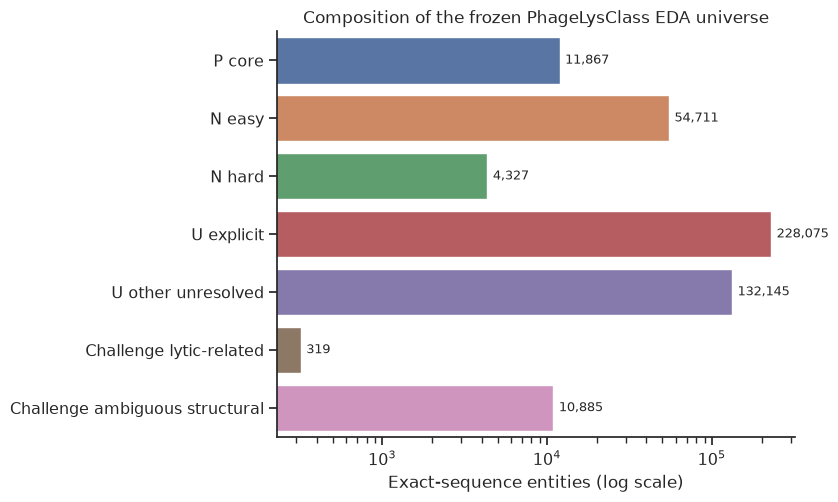

In [10]:
plot_data = (
    dataset_composition.loc[
        dataset_composition["section"].eq("primary_state")
    ]
    .copy()
)

plot_data["display_label"] = plot_data["label"].map(PRIMARY_LABELS)
plot_data["display_label"] = pd.Categorical(
    plot_data["display_label"],
    categories=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    ordered=True,
)

fig, ax = plt.subplots(figsize=(8.5, 5.2))

sns.barplot(
    data=plot_data,
    y="display_label",
    x="count",
    hue="display_label",
    order=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    hue_order=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    dodge=False,
    legend=False,
    ax=ax,
)

ax.set_xscale("log")
ax.set_xlabel("Exact-sequence entities (log scale)")
ax.set_ylabel("")
ax.set_title("Composition of the frozen PhageLysClass EDA universe")

for patch in ax.patches:
    width = patch.get_width()
    if np.isfinite(width):
        ax.annotate(
            f"{int(round(width)):,}",
            (width, patch.get_y() + patch.get_height() / 2),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
        )

sns.despine()
fig.tight_layout()
save_figure(fig, "E1_01_primary_state_composition")
plt.show()

### Figure E1.2 — PhageLysData Core subtype composition

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_02_core_subtype_composition.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_02_core_subtype_composition.pdf


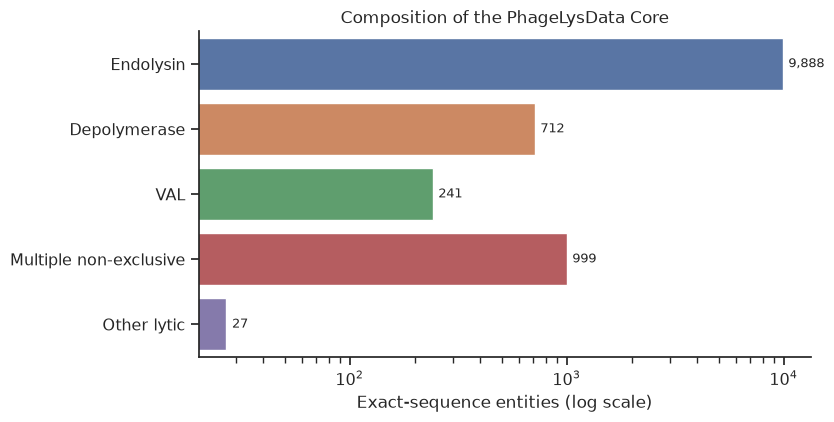

In [11]:
plot_data = (
    dataset_composition.loc[
        dataset_composition["section"].eq("core_subtype")
    ]
    .copy()
)

plot_data["display_label"] = plot_data["label"].map(CORE_SUBTYPE_LABELS)

fig, ax = plt.subplots(figsize=(8.5, 4.4))

sns.barplot(
    data=plot_data,
    y="display_label",
    x="count",
    hue="display_label",
    order=[CORE_SUBTYPE_LABELS[x] for x in CORE_SUBTYPE_ORDER],
    hue_order=[CORE_SUBTYPE_LABELS[x] for x in CORE_SUBTYPE_ORDER],
    dodge=False,
    legend=False,
    ax=ax,
)

ax.set_xscale("log")
ax.set_xlabel("Exact-sequence entities (log scale)")
ax.set_ylabel("")
ax.set_title("Composition of the PhageLysData Core")

for patch in ax.patches:
    width = patch.get_width()
    if np.isfinite(width):
        ax.annotate(
            f"{int(round(width)):,}",
            (width, patch.get_y() + patch.get_height() / 2),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
        )

sns.despine()
fig.tight_layout()
save_figure(fig, "E1_02_core_subtype_composition")
plt.show()

### Figure E1.3 — Length distributions across primary evidence states

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_03_length_primary_states.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_03_length_primary_states.pdf


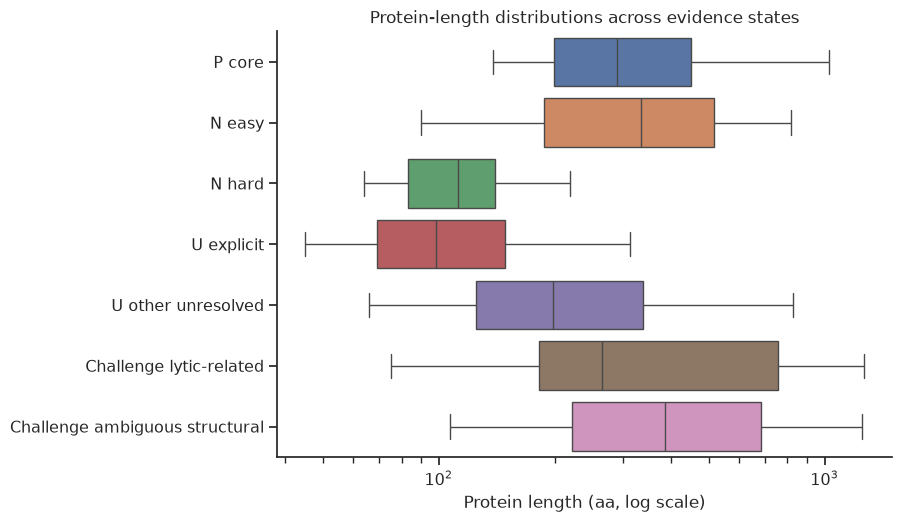

In [12]:
plot_data = df.loc[
    df["sequence_state"].isin(PRIMARY_ORDER),
    ["sequence_state", "sequence_length"],
].copy()

plot_data["display_label"] = plot_data["sequence_state"].map(PRIMARY_LABELS)

fig, ax = plt.subplots(figsize=(9.2, 5.4))

sns.boxplot(
    data=plot_data,
    y="display_label",
    x="sequence_length",
    hue="display_label",
    order=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    hue_order=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    dodge=False,
    legend=False,
    showfliers=False,
    whis=(5, 95),
    ax=ax,
)

ax.set_xscale("log")
ax.set_xlabel("Protein length (aa, log scale)")
ax.set_ylabel("")
ax.set_title("Protein-length distributions across evidence states")

sns.despine()
fig.tight_layout()
save_figure(fig, "E1_03_length_primary_states")
plt.show()

### Figure E1.4 — Length distributions of lytic proteins and negative backgrounds

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_04_length_global_ecdf.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_04_length_global_ecdf.pdf


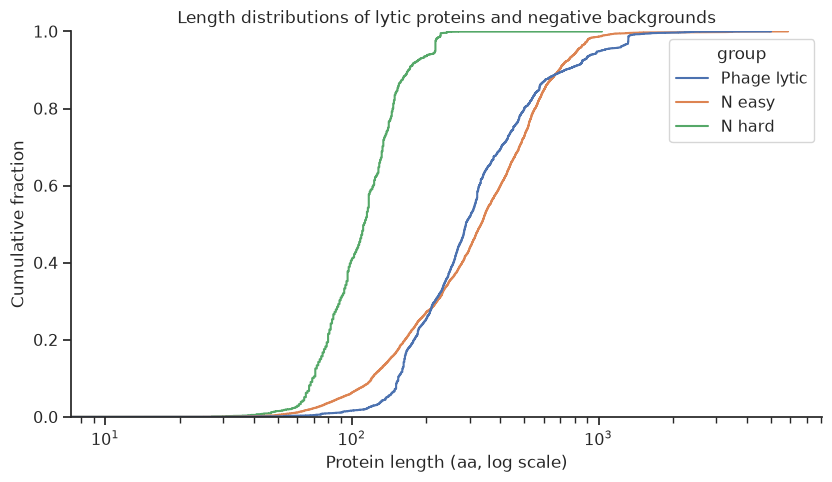

In [13]:
GLOBAL_GROUPS = ["P_core", "N_easy", "N_hard"]
GLOBAL_LABELS = {
    "P_core": "Phage lytic",
    "N_easy": "N easy",
    "N_hard": "N hard",
}

plot_data = df.loc[
    df["sequence_state"].isin(GLOBAL_GROUPS),
    ["sequence_state", "sequence_length"],
].copy()

plot_data["group"] = plot_data["sequence_state"].map(GLOBAL_LABELS)

fig, ax = plt.subplots(figsize=(8.5, 5.0))

sns.ecdfplot(
    data=plot_data,
    x="sequence_length",
    hue="group",
    hue_order=[GLOBAL_LABELS[x] for x in GLOBAL_GROUPS],
    ax=ax,
)

ax.set_xscale("log")
ax.set_xlabel("Protein length (aa, log scale)")
ax.set_ylabel("Cumulative fraction")
ax.set_title("Length distributions of lytic proteins and negative backgrounds")

sns.despine()
fig.tight_layout()
save_figure(fig, "E1_04_length_global_ecdf")
plt.show()

### Figure E1.5 — Length distributions of clean lytic subtypes

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_05_length_clean_subtypes_ecdf.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_05_length_clean_subtypes_ecdf.pdf


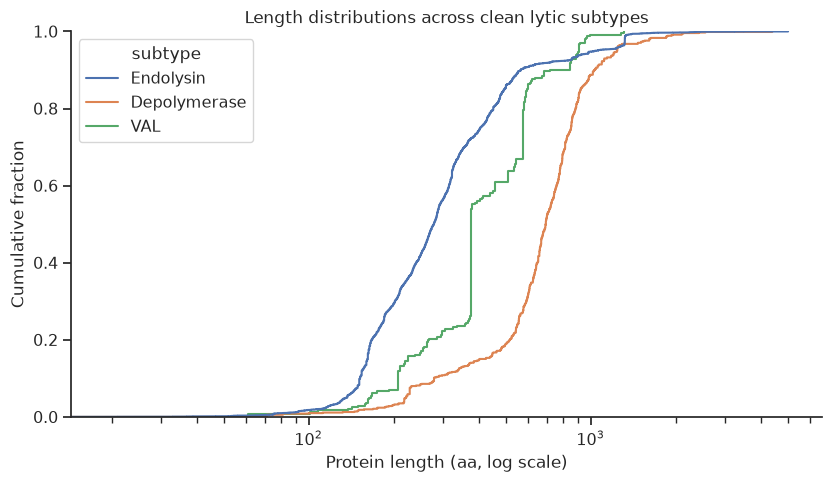

In [14]:
plot_data = clean_core.loc[
    clean_core["clean_subtype"].isin(CLEAN_SUBTYPE_ORDER),
    ["clean_subtype", "sequence_length"],
].copy()

plot_data["subtype"] = plot_data["clean_subtype"].map(CLEAN_SUBTYPE_LABELS)

fig, ax = plt.subplots(figsize=(8.5, 5.0))

sns.ecdfplot(
    data=plot_data,
    x="sequence_length",
    hue="subtype",
    hue_order=[CLEAN_SUBTYPE_LABELS[x] for x in CLEAN_SUBTYPE_ORDER],
    ax=ax,
)

ax.set_xscale("log")
ax.set_xlabel("Protein length (aa, log scale)")
ax.set_ylabel("Cumulative fraction")
ax.set_title("Length distributions across clean lytic subtypes")

sns.despine()
fig.tight_layout()
save_figure(fig, "E1_05_length_clean_subtypes_ecdf")
plt.show()

### Figure E1.6 — Retention under the 1024-aa canonical representation contract

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_06_representation_contract_coverage.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures/E1_06_representation_contract_coverage.pdf


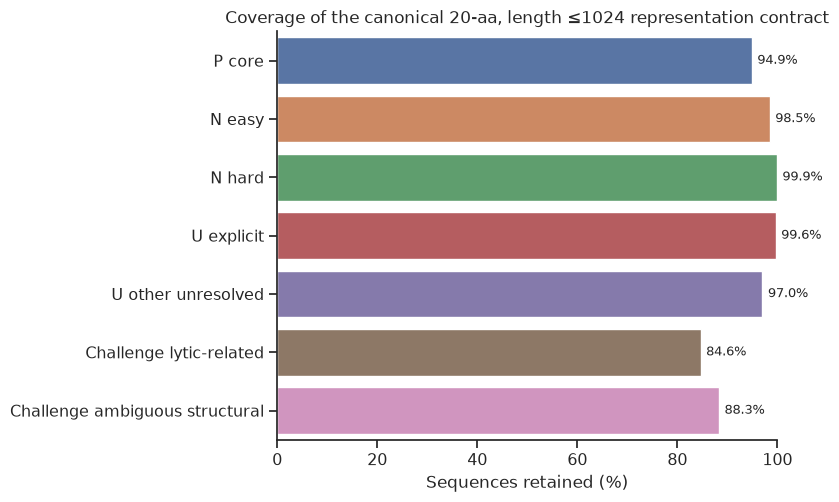

In [15]:
plot_data = representation_coverage.loc[
    (representation_coverage["representation_contract"].eq("plm_1024"))
    & (representation_coverage["section"].eq("primary_state"))
].copy()

plot_data["display_label"] = plot_data["label"].map(PRIMARY_LABELS)
plot_data["coverage_percent"] = 100 * plot_data["coverage_fraction"]

fig, ax = plt.subplots(figsize=(8.5, 5.2))

sns.barplot(
    data=plot_data,
    y="display_label",
    x="coverage_percent",
    hue="display_label",
    order=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    hue_order=[PRIMARY_LABELS[x] for x in PRIMARY_ORDER],
    dodge=False,
    legend=False,
    ax=ax,
)

ax.set_xlim(0, 100)
ax.set_xlabel("Sequences retained (%)")
ax.set_ylabel("")
ax.set_title("Coverage of the canonical 20-aa, length ≤1024 representation contract")

for patch in ax.patches:
    width = patch.get_width()
    if np.isfinite(width):
        ax.annotate(
            f"{width:.1f}%",
            (width, patch.get_y() + patch.get_height() / 2),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
        )

sns.despine()
fig.tight_layout()
save_figure(fig, "E1_06_representation_contract_coverage")
plt.show()

## 7. Closure

In [16]:
# Frozen primary-state counts from E0.
EXPECTED_PRIMARY_COUNTS = {
    "P_core": 11_867,
    "N_easy": 54_711,
    "N_hard": 4_327,
    "U_explicit": 228_075,
    "U_other_unresolved": 132_145,
    "challenge_lytic_related": 319,
    "challenge_ambiguous_structural": 10_885,
}

observed = df["sequence_state"].value_counts().to_dict()

for label, expected in EXPECTED_PRIMARY_COUNTS.items():
    assert int(observed.get(label, 0)) == expected

assert int(df["P_core"].sum()) == 11_867
assert len(core) == 11_867

# Clean subtype contract.
assert int((core["phage_lytic_subtype"] == "endolysin").sum()) == 9_888
assert int((core["phage_lytic_subtype"] == "depolymerase").sum()) == 712
assert int((core["phage_lytic_subtype"] == "virion_associated_lytic_enzyme").sum()) == 241

# Common 1024-aa/canonical contract from the frozen sequence universe.
assert int(df["eligible_1024_canonical20"].sum()) == 434_768

required_outputs = [
    DATASET_COMPOSITION_PATH,
    LENGTH_SUMMARY_PATH,
    REPRESENTATION_COVERAGE_PATH,
]

for path in required_outputs:
    assert path.is_file(), f"Missing output: {path}"

print("PASS — E1 dataset and evidence characterization completed.")
print()
print(f"dataset_composition.tsv   : {DATASET_COMPOSITION_PATH}")
print(f"length_summary.tsv        : {LENGTH_SUMMARY_PATH}")
print(f"representation_coverage.tsv: {REPRESENTATION_COVERAGE_PATH}")
print(f"figures                   : {FIGURE_DIR}")

PASS — E1 dataset and evidence characterization completed.

dataset_composition.tsv   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/dataset_composition.tsv
length_summary.tsv        : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/length_summary.tsv
representation_coverage.tsv: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/representation_coverage.tsv
figures                   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E1/figures
